# Reading XDMF time-series meshes with `pyramids-mesh`

**XDMF** (eXtensible Data Model and Format) pairs a small XML file describing the mesh and its variables with a bulky **`.h5`** HDF5 companion holding the actual arrays. It is the interchange format written by [meshio](https://github.com/nschloe/meshio) and read by ParaView/VTK. A temporal collection stores the same mesh across several time steps with per-step node and cell variables.

`pyramids-mesh` registers an `xdmf` **driver** that parses `out.xdmf` (plus its `out.h5`) into a `UgridDataset`/`Mesh2d`. This notebook reads a genuine meshio fixture and walks read → explore → plot → GIS.

## 2. Imports

The import below is all the setup this adds: `UgridDataset` is the object every driver hands back (a `Mesh2d` or `Network1d` wrapper). Importing from `pyramids` also puts its vendored GDAL/PROJ data in place for you, so nothing about it is order-sensitive in a notebook -- just import the names you use.

In [1]:
from pyramids.netcdf.ugrid import UgridDataset
import numpy as np
from pathlib import Path
import matplotlib.pyplot as plt

## 3. Locate the data

The notebook lives in `docs/examples/`, so `examples/data/` is two levels up. We pass a `pathlib.Path` to the reader (never a string).

In [2]:
DATA = Path("../../examples/data")
src = DATA / "xdmf" / "out.xdmf"
sorted(p.name for p in src.parent.iterdir())

['SOURCE.txt', 'out.h5', 'out.xdmf']

## 4. Read the mesh

We name the driver explicitly: `driver="xdmf"`. `read_file` dispatches to it and returns a `UgridDataset` wrapping a `Mesh2d`.

In [3]:
ds = UgridDataset.read_file(src, driver="xdmf")
ds

UgridDataset(mesh='mesh2d', n_node=4, n_face=2, n_edge=0, variables=['phi', 'a'])

In [4]:
# reading switches matplotlib to Agg for headless safety; let cleopatra
# pick the notebook backend (inline) so the plots below embed
from cleopatra.config import Config
Config.set_matplotlib_backend()

'inline'

## 5. Explore the mesh

Node/face counts, CRS, the attached data variables and the bounding box. This fixture is deliberately tiny — 4 nodes, 2 triangles on the unit square — which makes it perfect for seeing the full connectivity table. It carries a node variable `phi` (time-varying, 5 steps) and a cell variable `a`; it declares no CRS, so `crs`/`epsg` are `None`.

In [5]:
{"n_node": ds.n_node, "n_face": ds.n_face,
 "epsg": ds.epsg, "crs": ds.crs,
 "variables": ds.data_variable_names,
 "bounds": tuple(round(b, 3) for b in ds.bounds)}

{'n_node': 4,
 'n_face': 2,
 'epsg': None,
 'crs': None,
 'variables': ['phi', 'a'],
 'bounds': (0.0, 0.0, 1.0, 1.0)}

`summary()` tabulates every data variable's count/min/max/mean/std.

In [6]:
ds.summary()

,count,min,max,mean,std
variable,,,,,
phi,20,0.0,1.0,0.5,0.353553
a,10,3.0,4.2,3.6,0.600000


`phi` is a time-varying node field (5 steps × 4 nodes); `a` is a per-cell value. The `summary()` above shows both.

## 6. Mesh geometry

The `Mesh2d` exposes node coordinates, the `(n_face, k)` face-node connectivity, per-face areas and centroids — all plain numpy arrays.

In [7]:
m = ds.mesh
fnc = m.face_node_connectivity.data
cen = np.asarray(m.face_centroids)
{"fnc_shape": fnc.shape, "first_element": fnc[0].tolist(),
 "centroids_shape": cen.shape,
 "mean_face_area": float(m.face_areas.mean())}

{'fnc_shape': (2, 3),
 'first_element': [0, 1, 2],
 'centroids_shape': (2, 2),
 'mean_face_area': 0.5}

A `(n_face, 3)` table means every element is a triangle. Centroids come back `(2, n_face)`.

## 7. Wireframe

`plot_outline()` draws the bare element skeleton — the fastest way to read the mesh's shape and where it is refined.

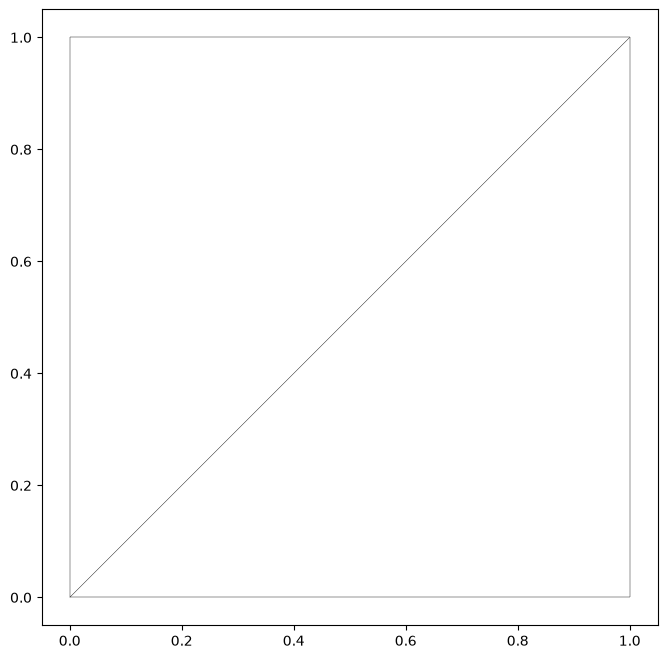

In [8]:
ds.plot_outline()

## 8. Data map

`phi` is a time-varying node field (5 steps × 4 nodes); `a` is a per-cell value. The `summary()` above shows both.

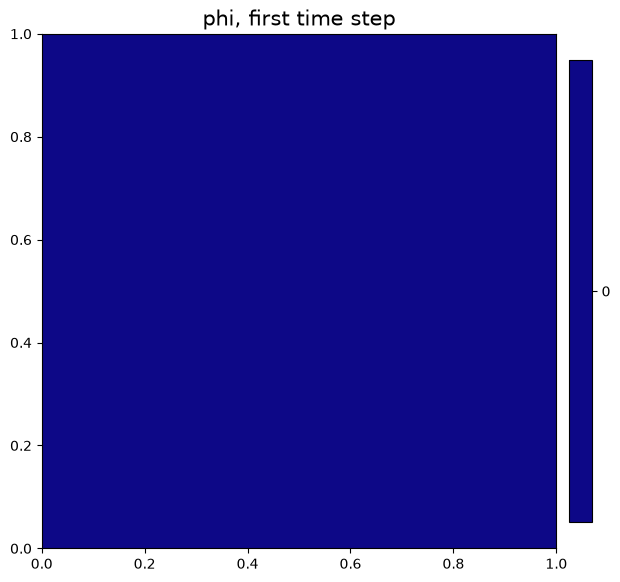

In [9]:
ds.plot("phi", cmap="plasma", colorbar=True,
        title="phi, first time step")

`phi` is time-varying `(5 steps, 4 nodes)`; the renderer draws the first step. With only two triangles the colouring is coarse — this file is a minimal meshio fixture, ideal for seeing the whole connectivity table at once (below).

## 9. GIS operations for free

The mesh is a pyramids object, so the vector/GIS layer applies unchanged. Convert to a GeoDataFrame — one polygon per element. `to_geodataframe()` returns just the geometry column, so we attach each element's **area** and let geopandas colour by it; smaller cells reveal where the mesh is refined.

In [10]:
gdf = ds.to_geodataframe()
gdf["face_area"] = ds.mesh.face_areas
gdf.head()

,geometry,face_area
0,"POLYGON ((0 0, 1 0, 1 1, 0 0))",0.5
1,"POLYGON ((0 0, 1 1, 0 1, 0 0))",0.5


Colour the elements by area with geopandas — the per-element column rides along with the geometry:

<Axes: xlabel='x', ylabel='y'>

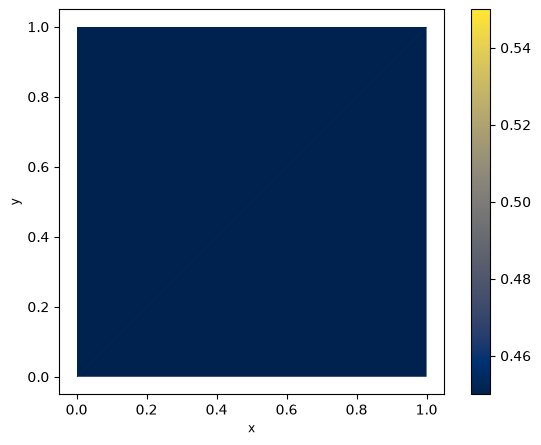

In [11]:
gdf.plot(column="face_area", cmap="cividis", figsize=(7, 5),
         legend=True)

The **bounding polygon** is the dissolved outer hull — the mesh's true footprint — drawn here in red over the wireframe.

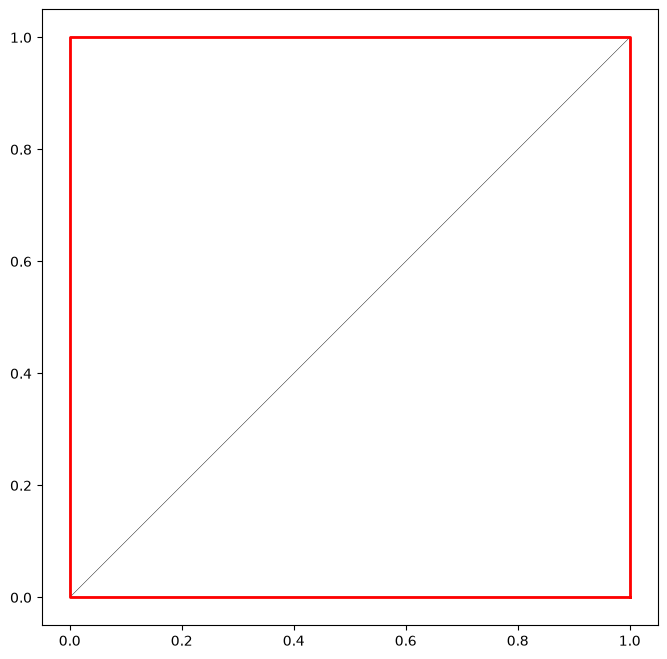

In [12]:
poly = ds.bounding_polygon()
ax = ds.plot_outline().ax
xs, ys = poly.exterior.xy
ax.plot(xs, ys, color="red", lw=2)

**Connectivity.** `sparse_adjacency()` is the node-node adjacency (SciPy sparse); `connected_components()` labels each node's component. One component = one unbroken mesh.

In [13]:
adj = ds.sparse_adjacency()
comp = ds.connected_components()
{"adjacency_shape": adj.shape, "nnz": int(adj.nnz),
 "n_components": int(np.unique(comp).size)}

{'adjacency_shape': (2, 2), 'nnz': 2, 'n_components': 1}

`exterior_edges()` returns the boundary edges (the mesh rim); `circumcenters()` the triangle circumcentres (the dual-mesh vertices used in finite-volume schemes).

In [14]:
ext = ds.exterior_edges()
cc = ds.circumcenters()
{"exterior_edges": int(ext.shape[0]),
 "circumcenters_shape": cc.shape}

{'exterior_edges': 4, 'circumcenters_shape': (2, 2)}

**Spatial subset.** `subset_by_bounds` keeps only faces inside a box, renumbering the connectivity. We take the mesh's own bounds and crop to its lower-left quadrant.

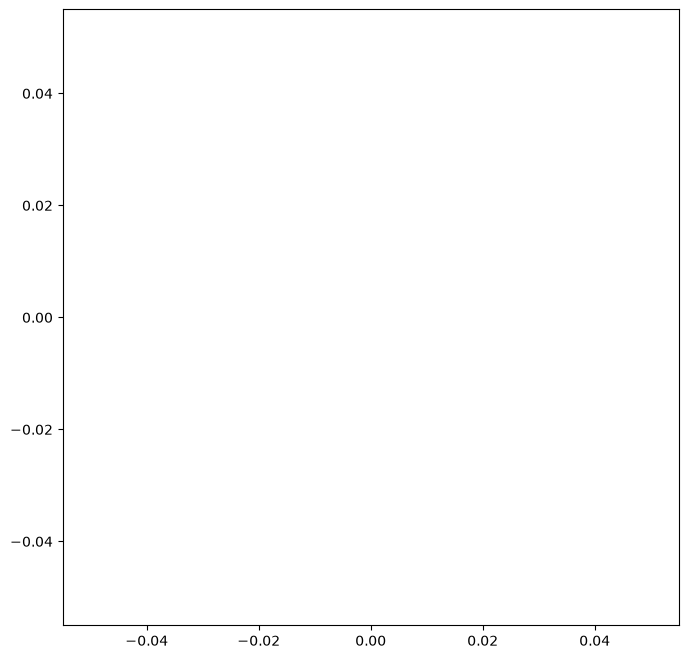

In [15]:
x0, y0, x1, y1 = ds.bounds
sub = ds.subset_by_bounds(x0, y0, (x0 + x1) / 2, (y0 + y1) / 2)
sub.plot_outline()

Only the faces inside the quadrant survive, with their connectivity renumbered:

In [16]:
{"faces_kept": sub.n_face, "of_total": ds.n_face}

{'faces_kept': 0, 'of_total': 2}

**Export.** `to_file` writes the mesh through any writer driver — here an SMS `2dm` grid in a temp folder.

In [17]:
import tempfile
out = Path(tempfile.gettempdir()) / "out.2dm"
ds.to_file(out, driver="2dm")
{"written": out.name, "exists": out.exists()}

{'written': 'out.2dm', 'exists': True}

And `to_xarray()` hands the mesh and its variables to the xarray ecosystem:

In [18]:
xds = ds.to_xarray()
type(xds).__name__, list(xds.data_vars)

('Dataset',
 ['mesh2d', 'mesh2d_node_x', 'mesh2d_node_y', 'mesh2d_face_nodes', 'phi', 'a'])

## 10. What needs more than a mesh

- **`to_crs(epsg)`** needs a source CRS. the XDMF fixture declares no CRS, so `ds.epsg is None`, so `to_crs` is skipped.
- **`rasterize_like` / `regrid`** need a *reference grid* to sample onto; with only the mesh in hand there is no target, so they are out of scope for this read-only tour.

## Takeaway

`UgridDataset.read_file(path, driver="xdmf")` turns the native xdmf grid into a first-class pyramids mesh. Exploration, plotting, GeoDataFrame conversion, bounding polygons, connectivity analysis, spatial subsetting and export are all inherited from pyramids — `pyramids-mesh` only added the reader.